In [1]:
import numpy as np
from scipy.integrate import simpson
import camb
import pandas as pd
import pylab as pl
import matplotlib as mpl
from camb import model,initialpower
from os.path import join as opj
#from scipy.special import erfc

In [2]:
def load_cls_theory(file, lmax, path = 'theory_cls'):
    # Load the file
    data = np.loadtxt(opj(path, file))
    spectrum_row = data[0] if data.ndim > 1 else data
    # Limit to lmax
    cls = spectrum_row[:lmax + 1]
    return cls

def get_correlation_coefficient(cov_mat_ell, cl_kI_ell, cl_kk, nfields=9, lmax=1500):
    rho_l_2 = np.zeros(lmax+1)
    for l in range(2, lmax+1):
        cov_mat = cov_mat_ell[:,:,l]
        cl_kI = cl_kI_ell[:,l]
        inv_cov_mat = np.linalg.inv(cov_mat)
        rho_l_2[l] = np.dot(cl_kI,np.dot(inv_cov_mat, cl_kI))
    return np.sqrt(rho_l_2/cl_kk)

### define matter lensing/galaxy kernels

In [3]:
def Dz(z,gamma_0,gamma_a):
    gamma = gamma_0 + gamma_a*z/(1.+z)
    z_integral = np.linspace(0.,z,500)
    integrand_dz = (results.get_Omega('cdm',z=z_integral)+results.get_Omega('baryon',z=z_integral)+results.get_Omega('neutrino',z=z_integral))**gamma/(1.+z_integral)
    return np.exp(-simpson(integrand_dz,x=z_integral))


def lens_ker(chis,zs,H_z):  
    ## check the lensing kernel for consistency (checked)
    W_k = (3.*Om0*(H0**2)*chis*(1.+zs)*(chistar-chis))/(2.*chistar*c*H_z)
    #W_k = (3.*Om0*(H0**2)*chis*(1.+zs)*(chistar-chis))/(2.*chistar)	 # removed c * H_z
    return W_k


def gal_ker(dist,zs,alpha,bias,chis,H_z):
    
    W_g = np.zeros(shape=(2,len(zs)))
    
    dist = dist/simpson(dist,x=zs)
    W_g[0,:] = bias*dist

    for i in range(len(zs)):
	    
	    zs_intgrl = zs[i:]
	    ch_intgrl = chis[i:]
	    H_z_intgrl = H_z[i:]
	    dist_intgrl = dist[i:]
    
	    integrand = (1.-ch_intgrl[0]/ch_intgrl)*(alpha-1.)*dist_intgrl
	    val_intgrl = simpson(y=integrand,x=zs_intgrl)

	    W_g[1,i] = (3.*Om0*(H0**2)*chis[i]*(1.+zs[i]))*val_intgrl/(2.*c*H_z[i])

    return (W_g[0,:]+W_g[1,:])

### set free parameters

In [4]:
nside = 2048

lmin = 0
lmax = 4000

kmin = 1e-4
kmax = 30.0
c = 3.e5

bias = 1.3 #*np.array([0.95503496, 0.89696663, 0.90705486, 0.9100578, 0.87373673, 0.90124658, 0.89613075, 0.92179589])
alpha = 1.
bias_evol = True

gamma_0 = 6./11.  # 6/11
gamma_a = 0.

zbins_start = 1
zbins_end = 8

zmin_kk = 0
zmax_kk = 100
spacing_kk = 1000

### matter power spctra

In [5]:
infile_b_dIdz = '../data/interpolated_b_dIdz.csv'
infile_dIdz = '../data/interpolated_dIdz.csv'
infile_dist = '../data/gal_dist_tomographic_bins.txt'

In [6]:
# matter power spectra at redshift z = 0
pars = camb.set_params(WantTransfer=True,NonLinear='NonLinear_both',num_nu_massless = 2.046,
					    nu_mass_degeneracies=[0.0],share_delta_neff=True,nu_mass_fractions=[1.0],
					    nu_mass_numbers=[1],MassiveNuMethod='Nu_trunc',H0=67.32117,ombh2=0.0223828,omch2=0.1201075,
					    mnu=0.06451439,omk=0,tau=0.05430842)


pars.Transfer.high_precision=True
pars.Transfer.kmax=1.3464234
pars.InitPower.set_params(parameterization=1,nt=0,ns=0.9660499,As=2.100549e-09)
pars.InitPower.At=0.0
pars.Reion.helium_delta_redshift = 0.5
pars.Reion.helium_redshiftstart = 6.0
pars.set_for_lmax(lmax=lmax,lens_potential_accuracy=0)
pars.NonLinearModel.set_params(halofit_version='original')
pars.NonLinearModel.Min_kh_nonlinear = 0.15
pars.SourceTerms.limber_phi_lmin = 100
pars.SourceTerms.limber_windows = True
pars.set_matter_power(redshifts=[0.], kmax=kmax, nonlinear=True, accurate_massive_neutrino_transfers=False)
pars.InitPower.k_min = kmin
pars.DoLensing = True

results = camb.get_results(pars)
chistar = results.conformal_time(0)-results.tau_maxvis

H0 = results.hubble_parameter(z=0.0)
Om0 = results.get_Omega('cdm',z=0)+results.get_Omega('baryon',z=0)+results.get_Omega('neutrino',z=0)

print ('Value of Hubble cosntant:',H0)
print ('Value of Density Parameter:',Om0)
print (r'Value of sigma_8:',results.get_sigma8_0())

gal_dist = np.loadtxt(infile_dist)
b_dIdz_dist = pd.read_csv(infile_b_dIdz, comment='#')
dIdz_dist = pd.read_csv(infile_dIdz, comment='#')

z_cib = dIdz_dist['z'].values
b_dIdz = b_dIdz_dist['b_dIdz'].values
dIdz = dIdz_dist['dIdz'].values
#b_dIdz = np.where(z_cib<=0.01, 0, b_dIdz)   # setting low z to zero

## create cib distribution bins
zbins = [0.0, 0.3, 0.6, 0.8, 1.0, 1.2, 1.4, 1.8, 2.2, 3.0, 6.0]
cib_dist = np.zeros((len(z_cib), len(zbins)+1))
cib_dist[:,0] = z_cib
for ii in range(1, len(zbins)):
    cib_dist[:,ii] = np.where((cib_dist[:,0] > zbins[ii-1]) & (cib_dist[:,0] < zbins[ii]), b_dIdz, 0)

PK = camb.get_matter_power_interpolator(pars,nonlinear=True,hubble_units=False,k_hunit=False,kmax=kmax,
                                            var1=model.Transfer_tot,var2=model.Transfer_tot,zmax=110.)

Value of Hubble cosntant: 67.32116999998941
Value of Density Parameter: 0.3144247685310203
Value of sigma_8: 0.8111274619798821


### emissivity plot

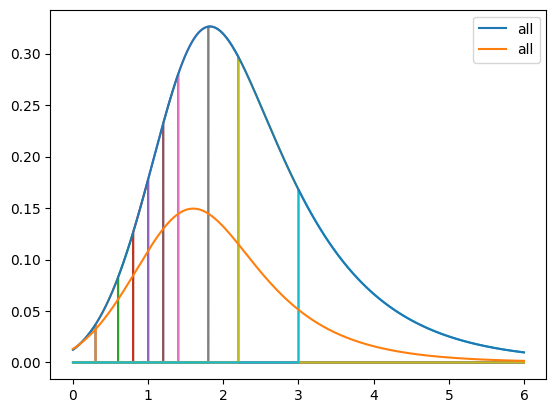

In [7]:
for ii in range(1,11):
    pl.plot(cib_dist[1:-1,0], cib_dist[1:-1,ii])
    #pl.plot(gal_dist[1:-1,0], gal_dist[1:-1,ii])
pl.plot(cib_dist[1:-1,0], b_dIdz[1:-1], label='all')
#pl.plot(cib_dist[1:-1,0], dIdz[1:-1], label='all')
pl.legend()
pl.show()

In [8]:
def cib_bias_z(zs):
    b0, b1, b2 = 0.94, 0.66, 0.04
    return b0 + b1*zs + b2*zs**2

cib_bias = cib_bias_z(cib_dist[:,0])
dIdz_corr = b_dIdz / cib_bias

CIB monopol at 545 GHz : 0.324 MJy/sr


Text(0.5, 1.0, 'bias corrected emissivity')

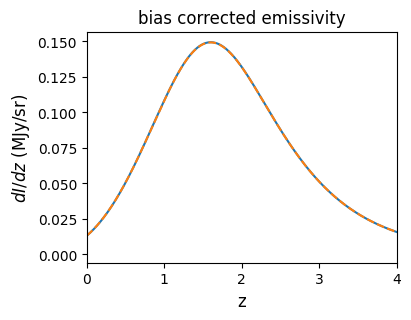

In [9]:
## monopole cib at 545 GHz

I_545 = simpson(dIdz, x=cib_dist[:,0])
print(r'CIB monopol at 545 GHz : %1.3f MJy/sr' %I_545)

fig, ax = pl.subplots(1,1,figsize=[4,3])
ax.plot(cib_dist[:,0], dIdz)
ax.plot(cib_dist[:,0], dIdz_corr, '--')
ax.set_ylabel(r'$dI/dz$ (MJy/sr)', fontsize=12)
ax.set_xlabel('z', fontsize=12)
#ax.set_xscale('log')
ax.set_xlim(0.,4.)
ax.set_title('bias corrected emissivity')

### get auto cib, cross cib

In [7]:
## define for clkk
zmin_kk = 0.001
zmax_kk = 100
spacing_kk = 100
zs = np.geomspace(zmin_kk,zmax_kk,100*spacing_kk)
dz = (zs[2:]-zs[:-2])/2.
zs = zs[1:-1]
chis = results.comoving_radial_distance(zs)
H_z = results.hubble_parameter(zs) 

Wk = lens_ker(chis,zs,H_z)
#norm = simpson(Wk, x=zs)  # normalisation factor integrated upto z ~ 1000
cl_kk = np.zeros(shape=(lmax-lmin+1))
for l in range(lmin,lmax+1):
    k = (l+0.5)/chis
    w = np.ones(k.shape)
    w[k<kmin] = 0.
    w[k>kmax] = 0.

    Pk_z = PK.P(zs, k,grid=False) #* D_z[1:-1]**2 
    cl_kk[l] =  np.dot(dz,w*H_z*Wk**2*Pk_z/chis**2/c)

del dz, H_z, chis    

In [28]:
#b_dIdz = np.where(cib_dist[:,0]<0.01, 0, b_dIdz)

## define for cibxcib and cibxkappa
dz = (cib_dist[2:,0]-cib_dist[:-2,0])/2.
zs = cib_dist[1:-1,0]

chis = results.comoving_radial_distance(zs)
H_z = results.hubble_parameter(zs)
Wk = lens_ker(chis,zs,H_z)
#Wk /= norm #simpson(Wk, x=zs)
Wcib = b_dIdz[1:-1]
#Wcib2 = b_dIdz[1:-1] * (np.sqrt(H_z)/chis)
Wcib2 = np.roll(b_dIdz[1:-1], -400)

Wcib = np.where(cib_dist[1:-1,0] > 5.6, 0, Wcib)
Wcib2 = np.where(cib_dist[1:-1,0] > 5.6, 0, Wcib2)

Wcib /= simpson(Wcib, x=zs)
Wcib2 /= simpson(Wcib2, x=zs)
#Wcib2 = np.where(cib_dist[1:-1,0] < 0.2, 0, Wcib2)

window_cib = camb.sources.SplinedSourceWindow(source_type='counts')
window_cib.set_table(z=zs[:-400:10], W=Wcib2[:-400:10])

cl_cib_tot = np.zeros(shape=(lmax-lmin+1))
cl_k_cib_tot = np.zeros(shape=(lmax-lmin+1))

for l in range(lmin,lmax+1):
    k = (l+0.5)/chis
    w = np.ones(k.shape)
    w[k<kmin] = 0.
    w[k>kmax] = 0.

    Pk_z = PK.P(zs,k,grid=False) #* D_z[1:-1]**2 
    cl_cib_tot[l] = np.dot(dz,w*H_z*Wcib2**2*Pk_z/chis**2/c)
    cl_k_cib_tot[l] = np.dot(dz,w*H_z*Wk*Wcib2*Pk_z/chis**2/c)

del dz, H_z, chis

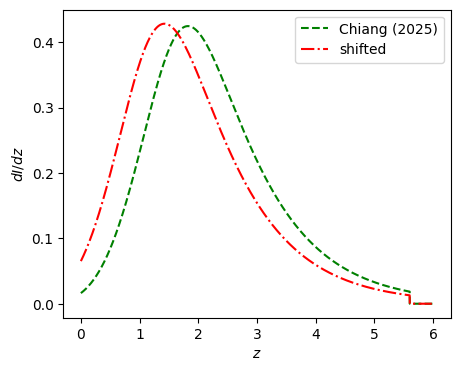

In [29]:
fig, ax = pl.subplots(1,1, figsize=[5,4])
ax.plot(zs, Wcib, 'g--', label=r'Chiang (2025)')
ax.plot(zs, Wcib2, 'r-.', label=r'shifted')

ax.set_ylabel(r'$dI/dz$')
ax.set_xlabel(r'$z$')
ax.legend()
pl.savefig('pdfs/dIdz_cib.pdf', bbox_inches='tight')

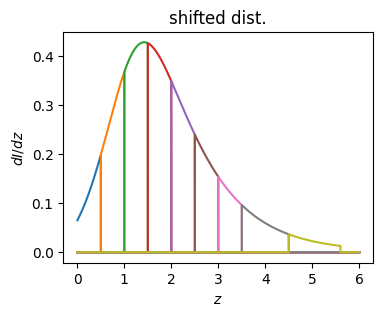

In [10]:
## create cib distribution bins
zbins = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.5, 6.0]
cib_dist = np.zeros((len(z_cib), len(zbins)+1))
cib_dist[:,0] = z_cib

dist_temp = np.roll(b_dIdz, -400)
dist_temp = np.where(cib_dist[:,0] > 5.6, 0, dist_temp)
dist_temp /= simpson(dist_temp, x=z_cib)

for ii in range(1, len(zbins)):
    cib_dist[:,ii] = np.where((cib_dist[:,0] > zbins[ii-1]) & (cib_dist[:,0] < zbins[ii]), dist_temp, 0)

fig, ax = pl.subplots(1,1, figsize=[4,3])
for ii in range(1,len(zbins)):
    ax.plot(cib_dist[1:-1,0], cib_dist[1:-1,ii])
#ax.plot(cib_dist[1:-1,0], b_dIdz[1:-1], label='all')
#pl.plot(cib_dist[1:-1,0], dIdz[1:-1], label='all')
#ax.legend()
ax.set_ylabel(r'$dI/dz$')
ax.set_xlabel(r'$z$')
ax.set_title('shifted dist.')
#ax.legend('shifted dist.')
pl.savefig('pdfs/dIdz_bins.pdf', bbox_inches='tight')
pl.show()

### plot power spectra

In [49]:
#zs = cib_dist[1:-1,0]
# Wcib = b_dIdz[1:-1]
# #Wcib = np.roll(b_dIdz[1:-1], -800)
# #Wcib = np.where(cib_dist[1:-1,0] > 5., 0, Wcib)
# pl.plot(cib_dist[1:-1,0],Wcib)

In [50]:
# ell = np.arange(lmin, lmax+1)
# fig, ax = pl.subplots(1,1,figsize=[4,3])
# #ax.plot(ell, cl_kk, label=r'$\kappa \times \kappa$')
# ax.plot(ell, cl_k_cib_tot, label=r'$\kappa \times CIB$')
# ax.plot(ell, cl_cib_tot, label=r'$CIB \times CIB$')
# ax.plot(ell, np.sqrt(cl_kk*cl_cib_tot), label='GM')
# #ax.plot(zs, intg_k_cib-np.sqrt(intg_cib_cib*intg_k_k), label=r'diff')

# ax.set_ylabel(r'$C_l$', fontsize=12)
# ax.set_xlabel('l', fontsize=12)
# ax.set_yscale('log')
# ax.set_xscale('log')
# ax.set_xlim(50,4000)
# #ax.set_ylim(1e-8,1e-7)
# ax.legend(fontsize=10)
# pl.show()

In [14]:
# rho_l = (cl_k_cib)/np.sqrt(cl_kk*cl_cib)
# pl.plot(ell, rho_l)
# pl.xlim(50,2000)

### implement camb to generate power spectra

In [104]:
# zmin_kk = 0.001
# zmax_kk = 100
# spacing_kk = 200
# zs1 = np.geomspace(zmin_kk,zmax_kk,np.int64((zmax_kk-zmin_kk)*spacing_kk))
# zs1 = zs1[1:-1]
# chis = results.comoving_radial_distance(zs1)
# H_z = results.hubble_parameter(zs1)
# Wk1 = (3.*Om0*(H0**2)*(1+zs1)*chis*(chistar-chis))/(2.*chistar*c*H_z) * (np.sqrt(H_z)/chis) 
# del chis, H_z

# zmin_kk = 0.001
# zmax_kk = 1100
# spacing_kk = 200
# zs2 = np.geomspace(zmin_kk,zmax_kk,np.int64((zmax_kk-zmin_kk)*spacing_kk))
# zs2 = zs2[1:-1]
# chis = results.comoving_radial_distance(zs2)
# H_z = results.hubble_parameter(zs2)
# Wk2 = (3.*Om0*(H0**2)*(1+zs2)*chis*(chistar-chis))/(2.*chistar*c*H_z) #* (np.sqrt(H_z)/chis) 

# pl.plot(zs1, Wk1/simpson(Wk1,x=zs1))
# pl.plot(zs2, 2.85*Wk2/simpson(Wk2,x=zs2), '--')
# pl.loglog()
# pl.ylim(5e-3, 5e-2)
# pl.xlim(0.001, 100)
# del chis, H_z

In [78]:
window_k = camb.sources.SplinedSourceWindow(source_type='counts')
#window_k.set_table(z=zs2, W=Wk2)

pars.SourceWindows = [window_cib]  #, window_cib]

pars.SourceTerms.limber_windows = True
pars.SourceTerms.limber_phi_lmin = 100
pars.SourceTerms.counts_density = True
pars.SourceTerms.counts_redshift = False
pars.SourceTerms.counts_lensing = False
pars.SourceTerms.counts_radial = False
pars.SourceTerms.counts_velocity = False
pars.SourceTerms.counts_timedelay = False
pars.SourceTerms.counts_ISW = False
pars.SourceTerms.counts_potential = False
pars.SourceTerms.counts_evolve = False
pars.SourceTerms.line_basic = False
pars.SourceTerms.line_distortions = False
pars.SourceTerms.line_extra = False
pars.SourceTerms.line_reionization = False
pars.SourceTerms.use_21cm_mK = False

In [79]:
results = camb.get_results(pars)
cls = results.get_source_cls_dict(raw_cl=True, lmax=4000)

### plot lensing potential

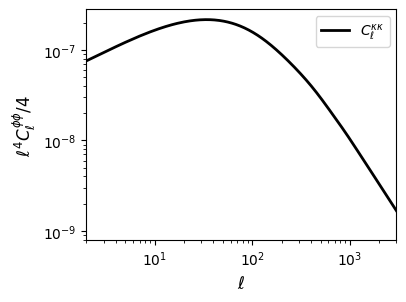

In [81]:
mpl.rcParams['font.size'] = 10

zbin = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 1.8, 2.2, 2.6, 3.0, 4.0, 5.0, 6.0]
bin_num = len(zbin)
Lmax = 4000
ell = np.arange(Lmax+1)
w = lambda ell : ell*(ell+1) / 2 / np.pi
#clkk2 = load_cls_theory('cl_kk_lmax_7000.dat', Lmax)
    
fig, ax = pl.subplots(1,1,figsize=[4,3])
## plot CIB545 x CIB545
ax.plot(ell, cl_kk[ell], 'k-', linewidth=2., label=r'$C_\ell^{\kappa\kappa}$')
#ax.plot(ell, cls['PxP'][ell] * (ell*(ell+1))**2 / 4, 'y--', label=r'PxP, camb')
#ax.plot(ell, cls['W1xW1'][ell] / 4 , 'y--', label=r'w1xw1')

ax.set_ylabel(r'$\ell^4 C_\ell^{\phi\phi}/4$', fontsize=12)
ax.set_xlabel(r'$\ell$', fontsize=12)
ax.set_xlim(2,3000)
ax.loglog()
ax.legend(fontsize=10)
#pl.savefig('pdfs/cl_kk.pdf', bbox_inches='tight')

### plot CIB power spectra

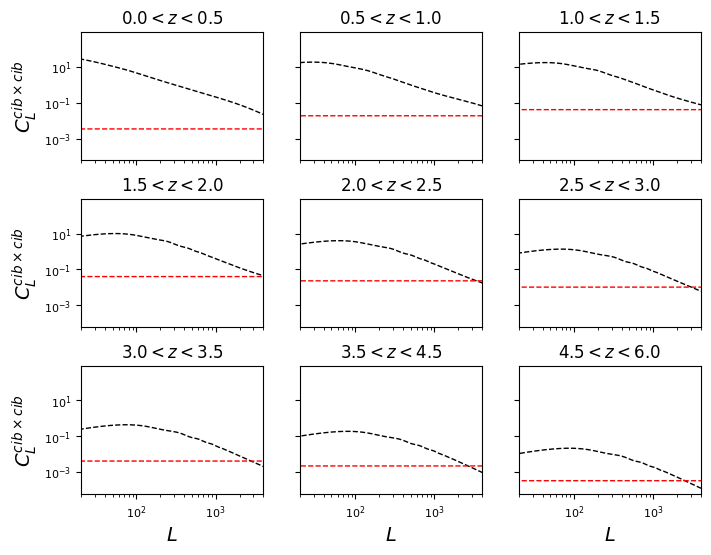

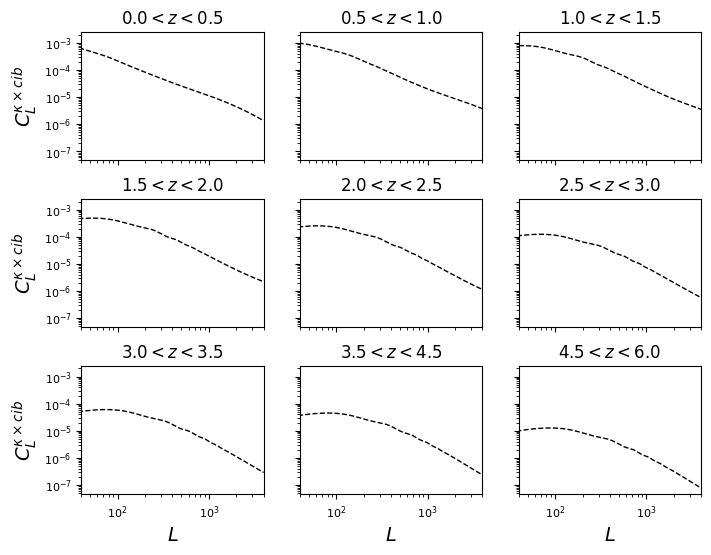

In [141]:
import pylab as pl
import matplotlib as mpl
mpl.rcParams['font.size'] = 8

Lmax = 4000
ell = np.arange(Lmax+1)
w = lambda ell : ell*(ell+1) / 2 / np.pi
MJy_to_muK = 1e6 / 58
zbins = [0.0, 0.5,  1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.5, 6.0]

fig1, axes = pl.subplots(3,3,figsize=[8,6], sharex=True, sharey=True)
pl.subplots_adjust(wspace=0.2, hspace=0.3)

for i, ax in enumerate(axes.flat):
    cl_cib = load_cls_theory('cl_cibcib_lmax_7000_bin_%s.dat' %(i+1), Lmax)
    nl_cib = load_cls_theory('nl_cib_lmax_7000_bin_%s.dat' %(i+1), Lmax, 'noise_cls')
    ax.loglog(ell, cl_cib[ell] * MJy_to_muK**2, 'k--',linewidth=1, label='theory')  # theroy auto spectra
    ax.loglog(ell, nl_cib[ell] * MJy_to_muK**2, 'r--',linewidth=1, label='noise')
    #print(nl_cib)
    ax.set_title(r'$%0.1f < z < %0.1f$' %(zbins[i], zbins[i+1]), fontsize=12)
    
    if i in [6, 7, 8]:
        ax.set_xlabel(r'$L$', fontsize=14)
    if i in [0, 3, 6]:
        ax.set_ylabel(r'$C_L^{cib \times cib}$', fontsize=14)
    
    ax.set_xlim(20, 4000)

pl.savefig(opj('pdfs','cib_auto_ps.pdf'),bbox_inches='tight')
pl.show()

'''
fig2, axes = pl.subplots(2,7,figsize=[15,4], sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    cl_g_cib = load_cls_theory('cl_g_cib_lmax_7000_bin_%s.dat' %(i+1), Lmax)    # theroy cross spectra
    ax.loglog(ell, cl_g_cib[ell] * MJy_to_muK, 'k--',linewidth=1, label='theory')
    ax.set_title(r'$%0.1f < z < %0.1f$' %(zbins[i], zbins[i+1]), fontsize=12)
    
    if i in [7,8,9,10,11,12,13]:
        ax.set_xlabel(r'$L$', fontsize=14)
    if i in [0,7]:
        ax.set_ylabel(r'$C_L^{cib \times gal}$', fontsize=14)
    
    ax.set_xlim(40, 4000)  
#pl.savefig(opj('plots','clkg.pdf'),bbox_inches='tight')
pl.show()
'''

fig2, axes = pl.subplots(3,3,figsize=[8,6], sharex=True, sharey=True)
pl.subplots_adjust(wspace=0.2, hspace=0.3)

for i, ax in enumerate(axes.flat):
    cl_k_cib = load_cls_theory('cl_k_cib_lmax_7000_bin_%s.dat' %(i+1), Lmax)    # theroy cross spectra
    ax.loglog(ell, cl_k_cib[ell] * MJy_to_muK, 'k--',linewidth=1, label='theory')
    ax.set_title(r'$%0.1f < z < %0.1f$' %(zbins[i], zbins[i+1]), fontsize=12)
    
    if i in [6,7,8]:
        ax.set_xlabel(r'$L$', fontsize=14)
    if i in [0,3,6]:
        ax.set_ylabel(r'$C_L^{\kappa \times cib}$', fontsize=14)
    
    ax.set_xlim(40, 4000)  
pl.savefig(opj('pdfs','cib_k_cross_ps.pdf'),bbox_inches='tight')
pl.show()

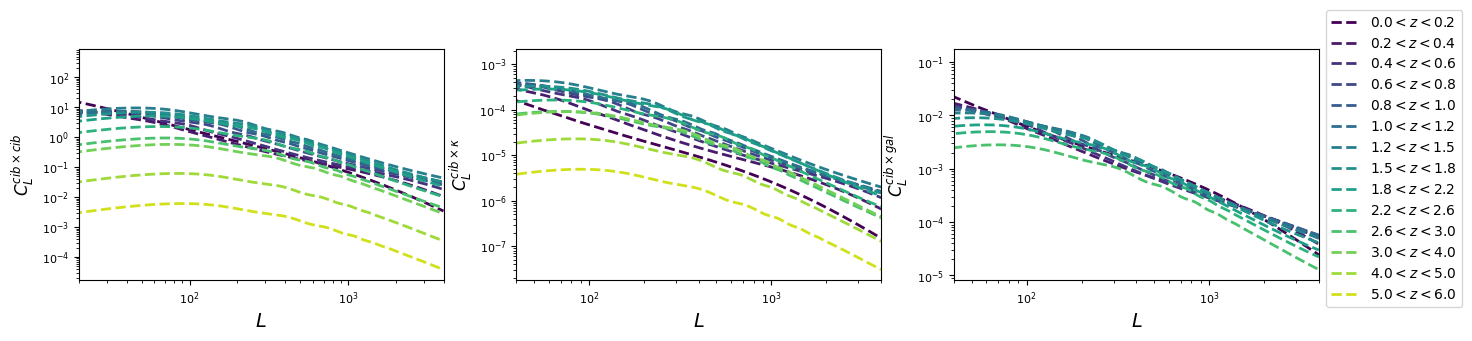

In [187]:
zbins = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 1.8, 2.2, 2.6, 3.0, 4.0, 5.0, 6.0]
colors = [pl.get_cmap('viridis')(i) for i in np.linspace(0,1,len(zbins))]

fig, (ax1,ax2,ax3) = pl.subplots(1,3,figsize=[16,3])
for i in range(len(zbins)-1):
    cl_cib = load_cls_theory('cl_cibcib_lmax_7000_bin_%s.dat' %(i+1), Lmax)
    ax1.loglog(ell, cl_cib[ell] * MJy_to_muK**2, '--', color=colors[i], linewidth=2, 
                  label=r'$%0.1f < z < %0.1f$' %(zbins[i], zbins[i+1]))  # theroy auto spectra

    cl_k_cib = load_cls_theory('cl_k_cib_lmax_7000_bin_%s.dat' %(i+1), Lmax)    # theroy cross spectra
    ax2.loglog(ell, cl_k_cib[ell] * MJy_to_muK, '--', color=colors[i], linewidth=2,
                  label=r'$%0.1f < z < %0.1f$' %(zbins[i], zbins[i+1]))

    cl_g_cib = load_cls_theory('cl_g_cib_lmax_7000_bin_%s.dat' %(i+1), Lmax)    # theroy cross spectra
    ax3.loglog(ell, cl_g_cib[ell] * MJy_to_muK, '--',  color=colors[i],linewidth=2, 
              label=r'$%0.1f < z < %0.1f$' %(zbins[i], zbins[i+1]))

ax1.set_xlabel(r'$L$', fontsize=14)
ax1.set_ylabel(r'$C_L^{cib \times cib}$', fontsize=12)
ax1.set_xlim(20, 4000)
#ax1.legend(fontsize=10)
    
ax2.set_xlabel(r'$L$', fontsize=14)
ax2.set_ylabel(r'$C_L^{cib \times \kappa}$', fontsize=12)
ax2.set_xlim(40, 4000) 
#ax2.legend(fontsize=10)
    
ax3.set_xlabel(r'$L$', fontsize=14)
ax3.set_ylabel(r'$C_L^{cib \times gal}$', fontsize=12)
ax3.set_xlim(40, 4000)  

ax3.legend(fontsize=10, bbox_to_anchor=(1., 1.2))

In [143]:
# zbins = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.5, 6.0]
# colors = [pl.get_cmap('viridis')(i) for i in np.linspace(0,1,len(zbins))]

# fig, (ax1,ax2,ax3) = pl.subplots(1,3,figsize=[16,3])

# cl_kk = load_cls_theory('cl_kk_lmax_7000.dat', Lmax)
# ax1.loglog(ell, cl_kk[ell], '--', color='black', linewidth=2)  # theroy auto spectra
# #ax1.loglog(ell, nlkk[ell], 'r--', label='N_l')
# ax1.set_xlabel(r'$L$', fontsize=14)
# ax1.set_ylabel(r'$C_L^{\kappa \times \kappa}$', fontsize=12)
# ax1.set_xlim(20, 4000)

# for i in range(len(zbins)-1):
#     cl_kg = load_cls_theory('cl_kg_lmax_7000_bin_%s.dat' %(i+1), Lmax)    # theroy cross spectra
#     ax2.loglog(ell, cl_kg[ell], '--', color=colors[i], linewidth=2,
#                   label=r'$%0.1f < z < %0.1f$' %(zbins[i], zbins[i+1]))

#     cl_gg = load_cls_theory('cl_gg_lmax_7000_bin_%s.dat' %(i+1), Lmax)    # theroy cross spectra
#     ax3.loglog(ell, cl_gg[ell], '--',  color=colors[i],linewidth=2, 
#               label=r'$%0.1f < z < %0.1f$' %(zbins[i], zbins[i+1]))
    
# ax2.set_xlabel(r'$L$', fontsize=14)
# ax2.set_ylabel(r'$C_L^{gal \times \kappa}$', fontsize=12)
# ax2.set_xlim(40, 4000) 
# #ax2.legend(fontsize=10)
    
# ax3.set_xlabel(r'$L$', fontsize=14)
# ax3.set_ylabel(r'$C_L^{gal \times gal}$', fontsize=12)
# ax3.set_xlim(40, 4000)  

# ax3.legend(fontsize=10, bbox_to_anchor=(1., 1.2))

### compare with Planck 

In [ ]:
# # planck CIB545xlensing data
# muK_to_Jy = 58
# l = np.array([417,543,670,797,923,1050,1177,1303,1430,1557,1683,1810,1937],dtype=float)
# val = np.array([28.92,29.05,23.38,20.12,21.37,18.32,15.38,19.36,18.78,12.94,12.67,11.70,7.13])
# stat = np.array([2.09,1.97,1.91,1.87,1.94,2.00,2.12,2.31,2.44,2.60,2.73,2.87,3.04])
# syst =  np.array([2.95,2.96,2.38,2.05,2.18,1.87,1.57,1.98,1.94,1.36,1.36,1.30,0.88])
# err = stat+syst
# l2Cl = val / 100.0 / l * muK_to_Jy
# l2Cl_err = err / 100.0 / l * muK_to_Jy
# data = np.column_stack([l, l2Cl, l2Cl_err])
# np.savetxt("data/CIB545xkappa.txt", data, header="l   l2C_l(Jy/sr)  error(Jy/sr)")

In [30]:
mpl.rcParams['font.size'] = 10

zbin = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.5, 6.0]
bin_num = len(zbin)
Lmax = 4000
ell = np.arange(Lmax+1)
w = lambda ell : ell*(ell+1) / 2 / np.pi
MJy_to_muK = 1e6 / 58
#cl_kk = load_cls_theory('cl_kk_lmax_7000.dat', Lmax)

cib_planck_fit = np.loadtxt("data/all_best_fit.txt")
ell_planck = cib_planck_fit[:,0]
cl_planck_fit_cib = cib_planck_fit[:,2] 

k_cib_planck_fit = np.loadtxt("data/CIB545xlensing_final.txt")
ell_fit_k_cib = k_cib_planck_fit[:,0]
cl_planck_fit_k_cib = k_cib_planck_fit[:,1]

cib_planck_data = np.loadtxt("data/CIB545x545.txt")
ell_data  = cib_planck_data[:,0]
cl_planck_data_cib  = cib_planck_data[:,1]
cl_planck_error_cib = cib_planck_data[:,2]

k_cib_planck_data = np.loadtxt("data/CIB545xkappa.txt")
ell_data_k_cib  = k_cib_planck_data[:,0]
cl_planck_data_k_cib  = k_cib_planck_data[:,1]
cl_planck_error_k_cib = k_cib_planck_data[:,2]

nl_planck_cib = np.ones(Lmax+1) * 1690  # shot noise for 545 x 545

cl_cib = 0.
cl_k_cib = 0.
for i in range(bin_num):
    cl_cib += load_cls_theory('cl_cibcib_lmax_7000_bin_%s.dat' %(i+1), Lmax)
    cl_k_cib += load_cls_theory('cl_k_cib_lmax_7000_bin_%s.dat' %(i+1), Lmax)

In [31]:
from scipy.interpolate import interp1d
## compute reduced chi square
def red_chi2(ell_data, data, error, ell_fit, fit, dof):
    fit_func = interp1d(ell_fit, fit)
    chi2 = np.sum((data - fit_func(ell_data))**2 / error**2)
    return chi2/dof

auto_chi2_planck = red_chi2(ell_data, cl_planck_data_cib, cl_planck_error_cib, ell_planck, cl_planck_fit_cib + 1690, len(ell_data)) 
auto_chi2_calc = red_chi2(ell_data, cl_planck_data_cib, cl_planck_error_cib, ell, cl_cib_tot[ell]*1e12 + 1690, len(ell_data))

cross_chi2_planck = red_chi2(ell_data_k_cib, cl_planck_data_k_cib * ell_data_k_cib, cl_planck_error_k_cib * ell_data_k_cib, \
                            ell_fit_k_cib, cl_planck_fit_k_cib, len(ell_data))
cross_chi2_calc = red_chi2(ell_data_k_cib, cl_planck_data_k_cib * ell_data_k_cib, cl_planck_error_k_cib * ell_data_k_cib,  \
                            ell, cl_k_cib_tot[ell] * ell * 1e6 * 2, len(ell_data))

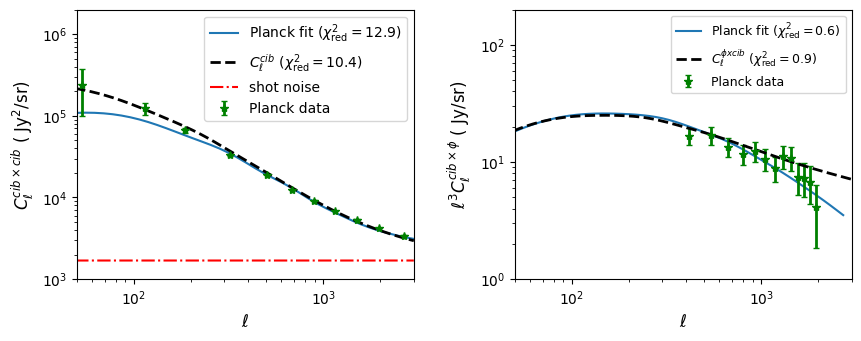

In [32]:
fig, (ax1,ax2) = pl.subplots(1,2,figsize=[10,3.5])
pl.subplots_adjust(wspace=0.3)

## plot CIB545 x CIB545
ax1.plot(ell_planck, cl_planck_fit_cib + 1690, '-', label=r'Planck fit $(\chi^2_{\rm red}=%0.1f)$' %auto_chi2_planck)
#ax1.plot(ell, cl_cib[ell] * 1e12 + 1.*nl_planck_cib, '--', label=r'z-bin added')  # converted from MJy to Jy
ax1.errorbar(ell_data, cl_planck_data_cib, yerr=cl_planck_error_cib, fmt='g*', 
                capsize=2, elinewidth=2, label=r'Planck data')
ax1.plot(ell, cl_cib_tot[ell] * 1e12 + 1690, 'k--', linewidth=2., label=r'$C_\ell^{cib}~(\chi^2_{\rm red}=%0.1f)$' %auto_chi2_calc)
ax1.plot(ell, nl_planck_cib, 'r-.', label=r'shot noise')

#ax1.plot(ell, cls['W1xW1'][ell] * 1e12 + 1.*nl_planck_cib, 'y:', label=r'W1xW1 (camb)')


ax1.set_ylabel(r'$C_\ell^{cib \times cib} ~ (~\mathrm{Jy^2/sr})$', fontsize=12)
ax1.set_xlabel(r'$\ell$', fontsize=12)
ax1.set_xlim(50,3000)
ax1.set_ylim(1e3, 2e6)
ax1.loglog()
ax1.legend(fontsize=10)


## plot kappa x CIB545
ax2.plot(ell_fit_k_cib, cl_planck_fit_k_cib, '-', label=r'Planck fit $(\chi^2_{\rm red}=%0.1f)$' %cross_chi2_planck)
#ax2.plot(ell, cl_k_cib[ell] * 1e6 * ell * 2, '--', label=r'z_bin added')  # converted MJy to Jy
ax2.errorbar(ell_data_k_cib, cl_planck_data_k_cib * ell_data_k_cib, yerr=cl_planck_error_k_cib * ell_data_k_cib,
                 fmt='g*', capsize=2, elinewidth=2, label=r'Planck data')
ax2.plot(ell, cl_k_cib_tot[ell] * ell * 1e6 * 2 , 'k--', linewidth=2., label=r'$C_\ell^{\phi x cib}~(\chi^2_{\rm red}=%0.1f)$' %cross_chi2_calc)
#ax2.plot(ell, cls['PxW1'][ell] * ell**3 * 1e6, 'y:', label=r'PxW1 (camb)')
#ax2.plot(ell, cls['W1xW2'][ell] * ell * 1e6 , 'y--', label=r'w1xw2')


## plot (clkk x cl_cib)^0.5
#ax2.plot(ell, np.sqrt(cl_kk*(cl_cib[ell] * 1e12 + nl_planck_cib)) , '--', color='black', label=r'$\sqrt{C_\ell^{\kappa\kappa} C_\ell^{CIB}}$')

ax2.set_ylabel(r'$\ell^3 C_\ell^{cib \times \phi} ~ (~\mathrm{Jy/sr})$', fontsize=12)
ax2.set_xlabel(r'$\ell$', fontsize=12)
ax2.set_xlim(50,3000)
ax2.set_ylim(1e0, 2e2)
ax2.loglog()
ax2.legend(loc='upper right', fontsize=9)
pl.savefig('pdfs/cib_auto_cross_fit_shift.pdf', bbox_inches='tight')

### calculate correlation coefficient

In [125]:
## load theory cls

MJy_to_muK = 1e6 / 58   # conversion factor for CIB spectra
Jy_to_muK = 1 / 58  

Lmax = 4000
clkk = load_cls_theory('cl_kk_lmax_7000.dat', Lmax)

zbins = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.5, 6.0]
z_num  = len(zbins)

# cl_g_g = []
# cl_k_g = []
# cl_g_cib = []
# for zbin in range(1, 12):
#     cl_g_g.append(load_cls_theory('cl_gg_lmax_7000_bin_%d.dat' %zbin, Lmax))
#     cl_k_g.append(load_cls_theory('cl_kg_lmax_7000_bin_%d.dat' %zbin, Lmax))
#     cl_g_cib.append(load_cls_theory('cl_g_cib_lmax_7000_bin_%d.dat' %zbin, Lmax))
# cl_g_g = np.array(cl_g_g)
# cl_k_g = np.array(cl_k_g)
# cl_g_cib = np.array(cl_g_cib)

cl_cib_cib = []
cl_k_cib = []
nl_cib = []
for zbin in range(1, z_num):
    cl_cib_cib.append(load_cls_theory('cl_cibcib_lmax_7000_bin_%d.dat' %zbin, Lmax))
    cl_k_cib.append(load_cls_theory('cl_k_cib_lmax_7000_bin_%d.dat' %zbin, Lmax))
    nl_cib.append(load_cls_theory('nl_cib_lmax_7000_bin_%d.dat' %zbin, Lmax,'noise_cls'))
cl_cib_cib = np.array(cl_cib_cib)
cl_k_cib = np.array(cl_k_cib)
nl_cib = np.array(nl_cib)

nlkk = np.load('noise_cls/nlkk_lmax_4000.npy')[:Lmax+1]
nlgg = np.load('noise_cls/nlgg_lmax_4000.npy')[:,:Lmax+1]

In [131]:
rho_cmb = np.sqrt(clkk / (clkk + nlkk))
#rho_gal_split = np.sqrt(np.sum(cl_k_g**2 / (cl_g_g), axis=0) / clkk)
#rho_gal_full = np.sqrt(np.sum(cl_k_g, axis=0)**2 / np.sum(cl_g_g, axis=0) / clkk)

rho_cib_split = np.sqrt(np.sum(cl_k_cib**2 / (cl_cib_cib + nl_cib), axis=0) / clkk)
rho_cib_full = np.sqrt(np.sum(cl_k_cib, axis=0)**2 / np.sum(cl_cib_cib + nl_cib, axis=0) / clkk)

### correlation  coefficient for planck best fit

In [97]:
# compute correlation coefficient from planck data

# interpolate at interval 10
def interpolate_1d(x,y):
    x=x[:49]
    y=y[:49]
    from scipy.interpolate import interp1d
    f=interp1d(x,y,kind='linear')
    x_new=np.arange(60, 2500,10)
    y_new=f(x_new)
    return x_new, y_new

cib_planck_fit = np.loadtxt("data/all_best_fit.txt")
ell_fit_cib = cib_planck_fit[:,0]
cl_planck_fit_cib = cib_planck_fit[:,2] 

k_cib_planck_fit = np.loadtxt("data/CIB545xlensing_final.txt")
ell_fit_k_cib = k_cib_planck_fit[:,0]
cl_planck_fit_k_cib = k_cib_planck_fit[:,1]

ell_bin , cl_planck_cib = interpolate_1d(ell_fit_cib, cl_planck_fit_cib)
_, cl_planck_k_cib = interpolate_1d(ell_fit_k_cib, cl_planck_fit_k_cib)

nl_planck_cib = 1690  # noise in Jy^2/sr

Lmax = 3000
clkk = load_cls_theory('cl_kk_lmax_7000.dat', Lmax)
#nlkk = np.load('noise_cls/nlkk_lmax_4000.npy')[:Lmax+1]

clkk_bin = clkk[np.arange(60,2500,10)]
rho_cib_planck = np.sqrt((cl_planck_k_cib / ell_bin / 2)**2 / (cl_planck_cib + nl_planck_cib) / (clkk_bin))

### full covariance matrix correlation coefficient

In [26]:
# from copy import deepcopy

# Lmin = 2
# Lmax = 3000
# ell = np.arange(Lmax+1)


# fields = 13
# cov_mat_ells = np.zeros((fields, fields, Lmax+1))
# cl_kI_ells = np.zeros((fields, Lmax+1))
# nlgg = np.load('noise_cls/nlgg_lmax_4000.npy')[:,:Lmax+1]
# for i in range(1,fields-1):
#     clgg = load_cls_theory('cl_gg_lmax_7000_bin_%d.dat' %(i), Lmax)
#     clkg = load_cls_theory('cl_kg_lmax_7000_bin_%d.dat' %(i), Lmax)
#     cl_g_cib = load_cls_theory('cl_g_cib_lmax_7000_bin_%s.dat' %(i), Lmax)
    
#     cl_kI_ells[i] = clkg
#     cov_mat_ells[i,i] = clgg + nlgg[i-1,:]
#     cov_mat_ells[i,0] = cov_mat_ells[0,i] = clkg
#     cov_mat_ells[i,fields-1] = cov_mat_ells[fields-1,i] = cl_g_cib

# ## cib auto and cross terms
# cl_cib, cl_k_cib, nl_cib = 0., 0., 0.
# for i in range(15):
#     cl_cib += load_cls_theory('cl_cibcib_lmax_7000_bin_%s.dat' %(i+1), Lmax)
#     nl_cib += load_cls_theory('nl_cib_lmax_7000_bin_%d.dat' %(i+1), Lmax,'noise_cls')
#     cl_k_cib += load_cls_theory('cl_k_cib_lmax_7000_bin_%s.dat' %(i+1), Lmax)
    
# cov_mat_ells[0,fields-1] = cov_mat_ells[fields-1,0] = cl_k_cib
# cov_mat_ells[fields-1,fields-1] = cl_cib + nl_cib


# ## cross galaxy redshift bin terms
# # for i in range(1,8):
# #     clgigj = load_cls_theory('cl_gg_lmax_7000_bin_%d%d.dat' %(i, i+1), Lmax,'theory_cls')
# #     cov_mat_ells[i,i+1] = cov_mat_ells[i+1,i] = clgigj

# # for i in range(1,7):
# #     clgigj = load_cls_theory('cl_gg_lmax_7000_bin_%d%d.dat' %(i, i+2), Lmax,'theory_cls')
# #     cov_mat_ells[i,i+2] = cov_mat_ells[i+2,i] = clgigj 


# clkk = load_cls_theory('cl_kk_lmax_7000.dat', Lmax)
# nlkk = np.load('noise_cls/nlkk_lmax_4000.npy')[:Lmax+1]
# cov_mat_ells[0,0] = (clkk + nlkk)
# cl_kI_ells[0] = deepcopy(clkk)

# # c_i = np.zeros((fields, Lmax+1))
# # for l in range(Lmin, Lmax+1):    
# #     c_i[:,l] = np.dot(np.linalg.inv(cov_mat_ells[:,:,l]), cl_kI_ells[:,l])
# # np.save('outputs/optimal_tracer_weights.npy', c_i)

# rho_cmb_gal_cib_full = get_correlation_coefficient(cov_mat_ells, cl_kI_ells, clkk, fields, lmax=Lmax)



# ################
# Lmin = 2
# Lmax = 3000
# ell = np.arange(Lmax+1)

# fields = 24
# cov_mat_ells = np.zeros((fields, fields, Lmax+1))
# cl_kI_ells = np.zeros((fields, Lmax+1))
# nlgg = np.load('noise_cls/nlgg_lmax_4000.npy')[:,:Lmax+1]
# for i in range(1,9):
#     clgg = load_cls_theory('cl_gg_lmax_7000_bin_%d.dat' %(i), Lmax)
#     clkg = load_cls_theory('cl_kg_lmax_7000_bin_%d.dat' %(i), Lmax)
#     cl_g_cib = load_cls_theory('cl_g_cib_lmax_7000_bin_%s.dat' %(i), Lmax)
    
#     cl_kI_ells[i] = clkg
#     cov_mat_ells[i,i] = clgg + nlgg[i-1,:]
#     cov_mat_ells[i,0] = cov_mat_ells[0,i] = clkg
#     cov_mat_ells[i,9] = cov_mat_ells[9,i] = cl_g_cib

# ## cib auto and lensing cross terms
# for i in range(9,24):
#     cl_cib = load_cls_theory('cl_cibcib_lmax_7000_bin_%s.dat' %(i-8), Lmax)
#     nl_cib = load_cls_theory('nl_cib_lmax_7000_bin_%d.dat' %(i-8), Lmax,'noise_cls')
#     cl_k_cib = load_cls_theory('cl_k_cib_lmax_7000_bin_%s.dat' %(i-8), Lmax)
#     cov_mat_ells[i,i] = cl_cib + nl_cib
#     cov_mat_ells[i,0] = cov_mat_ells[0,i] = cl_k_cib
#     cov_mat_ells[i,0] = cov_mat_ells[0,i] = cl_k_cib

# ## cross galaxy cib terms
# for i in range(1,9):
#     j = i+1
#     cl_g_cib = load_cls_theory('cl_g_cib_lmax_7000_bin_%s.dat' %(i), Lmax)
#     cov_mat_ells[i,j] = cov_mat_ells[j,i] = cl_g_cib

# ## cross galaxy redshift bin terms
# # for i in range(1,6):
# #     clgigj = load_cls_theory('cl_gg_lmax_7000_bin_%d%d.dat' %(i, i+1), Lmax,'theory_cls')
# #     cov_mat_ells[i,i+1] = cov_mat_ells[i+1,i] = clgigj

# # for i in range(1,5):
# #     clgigj = load_cls_theory('cl_gg_lmax_7000_bin_%d%d.dat' %(i, i+2), Lmax,'theory_cls')
# #     cov_mat_ells[i,i+2] = cov_mat_ells[i+2,i] = clgigj 
    
# clkk = load_cls_theory('cl_kk_lmax_7000.dat', Lmax)
# nlkk = np.load('noise_cls/nlkk_lmax_4000.npy')[:Lmax+1]
# cov_mat_ells[0,0] = (clkk + nlkk)
# cl_kI_ells[0] = deepcopy(clkk)

# # c_i = np.zeros((fields, Lmax+1))
# # for l in range(Lmin, Lmax+1):    
# #     c_i[:,l] = np.dot(np.linalg.inv(cov_mat_ells[:,:,l]), cl_kI_ells[:,l])
# # np.save('outputs/optimal_tracer_weights.npy', c_i)

# rho_cmb_gal_cib_split = get_correlation_coefficient(cov_mat_ells, cl_kI_ells, clkk, fields, lmax=Lmax)

### plot correlation coefficient

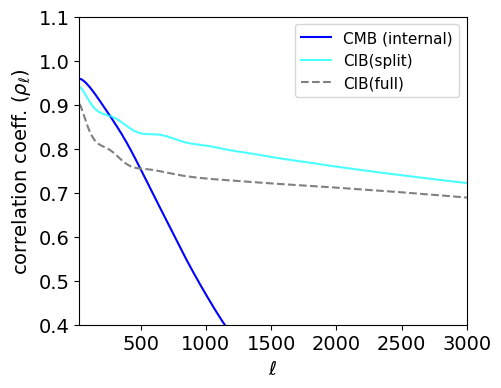

In [149]:
# plot optimal combination
import matplotlib as mpl
mpl.rcParams['font.size'] = 14
Lmax = 4000
ell = np.arange(Lmax+1)
#ell_bin = b.get_effective_ells()

fig, ax = pl.subplots(1,1, figsize=[5,4])

ax.plot(ell, rho_cmb[ell], '-', color='blue', label='CMB (internal)')
#ax.plot(ell, rho_gal_split[ell], color='green', alpha=0.7, label='LSST(split)')
#ax.plot(ell, rho_gal_full[ell], '--', color='green', label='LSST(full)')
ax.plot(ell, rho_cib_split[ell], color='cyan', alpha=0.7, label='CIB(split)')
ax.plot(ell, rho_cib_full[ell], '--', color='grey', label='CIB(full)')
#ax.plot(ell, rho_cmb_gal_cib_split[ell], '-.', color='purple', label='CMB+LSST+CIB(split)')
#ax.plot(ell, rho_cmb_gal_cib_full[ell], '--', color='magenta',  label='CMB+LSST+CIB(full)')

#ax.plot(ell_bin, rho_cib_planck, '-.', color='red', label='CIB(Planck)')



#ax.plot(ell, rho_cmb_lss_uncorr[ell], '-.', color='purple', label='CMB+LSS(uncorr.)')

#ax.plot(ell_bin, rho_cmb_lss_sims, '--^', color='blue', label='CMB-S4 + LSST')

pl.legend(fontsize=11) #, bbox_to_anchor=(1, 0.5))
ax.set_xlim(30, 3000)
ax.set_ylim(0.4,1.1)
#ax.set_yticks([0.4,0.6,0.8,1.0])
ax.set_ylabel(r'correlation coeff. $(\rho_\ell)$')
ax.set_xlabel(r'$\ell$')
#pl.title(r'correlation coefficient, $\rho_L$ (analytical)', fontsize=13)
pl.savefig('pdfs/rho_ell.pdf', bbox_inches='tight')
pl.show()

### bias corrected emissivity

### interpolate theory cib emissivity

In [ ]:
### read emissivity file

import pandas as pd

df = pd.read_csv('data/CIB_dIdz--best_fit_model.ecsv', comment='#')
zvals = df['z'].values[:61]  # redshift upto 50
CIB_b_dIdz = df['Planck 545 GHz'].values[:61]

In [ ]:
from scipy.interpolate import interp1d  

def interpolate_fitted_line(zval, fit_of_z,
                            dz_old=0.1, dz_new=0.001,
                            kind="cubic"):
    
    z_min, z_max = zval.min(), zval.max()
    z_new = np.arange(z_min, z_max + dz_new/2, dz_new)

    #interpolation
    f = interp1d(zval, fit_of_z, kind=kind, fill_value="extrapolate")
    y_new = f(z_new)

    df_new = pd.DataFrame({"z": z_new, "dIdz": y_new})
    outfile = "interpolated_dIdz.csv"
    df_new.to_csv( 'data/' + outfile, index=False)
    return df_new

# interpolate
df545_interp = interpolate_fitted_line(zvals, CIB_b_dIdz, dz_new=0.001)

In [ ]:
z_new = df545_interp['z'].values
dIdz_new = df545_interp['dIdz'].values

import pylab as pl
pl.plot(z_new, dIdz_new)
pl.xscale('log')

### Define emissivity model for CIB (Chiang et al 2025)

In [ ]:
## best-fit values from Table 2

# Physical constants (SI)
h  = 6.62607015e-34      # Planck constant [J s]
kB = 1.380649e-23        # Boltzmann constant [J/K]
c  = 2.99792458e8        # Speed of light [m/s]

# free parameters
a = np.exp(5.16)
b = 1.54
c = 2.83
d = 6.55

mu_0 = 2.55
C_mu = 0.60
s_T = 0.04
alph_T = 5

kappa_0 = 0.77
nu_0 = 353

Sig_d = np.exp(7.78)
beta_0 = 1.69
C_b = 0.37
sig_b = 0.71

## effective bias
b_0 = 0.94
b_1 = 0.66
b_2 = 0.04

In [ ]:
def planck_nu(nu, T):
    """
    Planck function B_nu(nu, T)  [SI units: W m^-2 Hz^-1 sr^-1]
    """
    nu = np.asarray(nu)
    T  = np.asarray(T)
    x = h * nu[..., None] / (kB * T) if T.ndim == 1 else h * nu / (kB * T)
    return (2.0 * h * nu**3 / c**2) / (np.exp(x) - 1.0)

def P_T(T, mu_T, s_T, alph_T):
    """
    Temperature PDF P(T).
    """
    T = np.asarray(T)
    pref = alph_T / 2.0 * np.exp(alph_T * mu_T + 0.5 * alph_T**2 * s_T**2)
    power = T**(-(1.0 + alph_T))
    arg = (alph_T * s_T - (np.log(T) - mu_T) / s_T) / np.sqrt(2.0)
    return pref * power * erfc(arg)


def rho_d(z, a, b, c, d):
    """
    Dust mass density rho_d(z) = a (1+z)^b / [1 + ((1+z)/c)^d]
    """
    zp1 = 1.0 + np.asarray(z)
    return a * zp1**b / (1.0 + (zp1 / c_rho)**d_rho)


def beta_mean_z(z, beta_0, C_b):
    """
    <beta> = beta_0 + C_beta * log(1+z)
    """
    z = np.asarray(z)
    return beta_0 + C_beta * np.log(1.0 + z)


def mu_T_z(z, mu_0, C_mu):
    """
    mu_T(z) = mu_0 + C_mu * log(1+z)
    """
    z = np.asarray(z)
    return mu_0 + C_mu * np.log(1.0 + z)


def P_beta(beta, z, sig_beta):
    """
    Normalized Gaussian P(beta) with mean mu_beta and std sigma_beta.
    """
    beta = np.asarray(beta)
    norm = 1.0 / (np.sqrt(2.0 * np.pi) * sig_b)
    return norm * np.exp(-0.5 * ((beta - mu_beta) / sig_b)**2)


def tau_exp(nu, z, kappa_0, Sigma_d, nu_0,
                    beta_0, C_beta, sig_beta,
                    n_beta=400, n_sig=5.0):
    """
    Eq. 13 in reference
    The integral over beta is done numerically with a Gaussian PDF
    """
    r = nu / nu_0

    # Mean of beta at this redshift
    mu_beta = beta_mean(z, beta0, C_beta)

    # integration grid
    beta_min = mu_beta - n_sig * sig_b
    beta_max = mu_beta + n_sig * sig_b
    beta_grid = np.linspace(beta_min, beta_max, n_beta)

    # P(beta) on the grid
    P = P_beta(beta_grid, mu_beta, sig_b)  # shape (n_beta,)

    # integrand shape: (N_nu, n_beta)
    r = np.atleast_1d(r)
    integrand = (r[:, None] ** beta_grid[None, :]) * P[None, :]

    # Numerical integral over beta
    expect = np.trapz(integrand, beta_grid, axis=1)  # shape (N_nu,)

    tau = kappa_0 * Sig_d * expect
    return tau


def Bnu_exp(nu, z, mu_0, C_mu, s_T, alph_T,
            n_T=400, nsig=5.0):
    """
    See Eq. 19 in reference
    Computed numerically over log T in [mu_T - nsig*s_T, mu_T + nsig*s_T].
    """
    muT = mu_T_of_z(z, mu0, C_mu)

    # Log-temperature grid
    x_min = muT - nsig * s_T
    x_max = muT + nsig * s_T
    x = np.linspace(x_min, x_max, n_T)
    T = np.exp(x)                      # T(x)
    
    # PDF and Planck function
    PT = P_T(T, muT, s_T, alpha_T)     # shape (n_T,)
    B  = planck_nu(nu[None, :], T[:, None])  # (n_T, n_nu)

    # numerical integration
    integrand = B * PT[:, None] * T[:, None]
    avg = np.trapz(integrand, x, axis=0)   # integrate over x

    # If input was scalar, return scalar
    return avg


def dust_emissivity(
    z, nu,
    a, b, c, d,
    Sig_d, kappa_0, nu_0,
    beta_0, C_b, sig_b,
    mu_0, C_mu, s_T, alph_T,
    n_T=400, nsig=5.0,
):
    """
    Emissivity j_nu(nu, z) as function of redshift
    all other parameters are best-fit values
    """
    nu = np.asarray(nu)

    # Dust density
    rho = rho_d(z, a, b, c_rho, d_rho)

    # Mean optical depth
    tau_avg = tau_exp(nu, z, kappa0, Sigma_d, nu0, beta0, C_beta, sigma_beta)

    # Mean Planck function
    B_avg = Bnu_exp(nu, z, mu0, C_mu, s_T, alpha_T, n_T=n_T, nsig=nsig)

    # Emissivity
    j_nu = rho / Sig_d * (1.0 - np.exp(-tau_avg)) * B_avg

    return j_nu    